# 서울 공공체육시설의 시간대별 접근성
## 공공체육시설의 시간대별 이용 기회와 공간 접근성

자료 수집일 **2026년10월31일**

**연구 질문:** 서울에서 공공체육시설이 많은 행정동과, 평일 저녁·주말에 가까운 시설을 이용할 수 있는 행정동은 일치하는가? 이러한 차이는 종목에 따라 어떻게 달라지는가?

시설의 ‘존재’와 ‘이용할 수 있는 시간’을 구분한다. 밀도(Density)와 거리 감쇠 접근성(Gravity-based Accessibility)을 산출하고, 공간 지도와 비공간 그래프를 통해 비교한다. 시간 미반영 접근성을 함께 계산해 거리 모형과 운영시간의 영향을 구분한다.

분석 대상은 원자료에서 공공체육시설로 분류된 **수영장·배드민턴장·테니스장·축구장·풋살장·농구장**이다. 복합센터와 내부 종목시설의 중복 집계를 줄이기 위해 생활체육관 등 상위·복합 분류는 제외한다. 단위는 **등록된 종목별 시설 항목**이며 건물·코트·정원 수와 다르다.

### 재현 방법

전체 패키지를 풀고 이 폴더에서 노트북을 실행한다. `pip install -r requirements.txt`로 의존성을 설치한다. 포함 원자료만으로 재계산하며 API 키와 네트워크는 필요하지 않다. `scripts/analyze.py`는 지표·그림·웹 데이터를, `scripts/schedules.py`는 시간 판정을 구현한다. 아래 모든 코드 셀을 실행한 결과가 저장되어 있다.


In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
from IPython.display import display,Image,Markdown
ROOT=Path.cwd()
assert (ROOT/'scripts/analyze.py').exists(), '패키지 최상위 폴더에서 실행한다.'
sys.path.insert(0,str(ROOT/'scripts'))
import analyze,verify
payload=analyze.main()
audit=payload['audit']
facilities=pd.DataFrame(payload['facilities'])
metrics=pd.DataFrame(payload['metrics'])
districts=pd.DataFrame(payload['districts'])
counts=pd.DataFrame(payload['summary'])


{
  "as_of": "2026-10-31",
  "season": "10월의 공휴일 아닌 통상 주간, 특정 주차 미지정",
  "source_total": 897,
  "public_total": 814,
  "selected_rows": 399,
  "unique": 398,
  "closed_records": 26,
  "outside_or_missing": [
    1091,
    1026,
    1490,
    1073,
    1074,
    1575,
    676,
    1494,
    1562,
    1144,
    1523,
    1103,
    1503,
    1513,
    1514
  ],
  "primary": 351,
  "district_count": 25,
  "dong_count": 427,
  "grid_count": 2425,
  "correlations": {
    "wed14": {
      "density_vs_access_spearman": 0.44058268404993167,
      "potential_vs_access_spearman": 0.9884508521945214
    },
    "wed20": {
      "density_vs_access_spearman": 0.3917099289764137,
      "potential_vs_access_spearman": 0.8696030942819473
    },
    "sat14": {
      "density_vs_access_spearman": 0.4348099504457381,
      "potential_vs_access_spearman": 0.9620092240280969
    },
    "sun14": {
      "density_vs_access_spearman": 0.4013616991520785,
      "potential_vs_access_spearman": 0.8947148840150949


## 1. 자료의 출처와 적합성

|자료|사용 항목·역할|출처 및 조건|
|---|---|---|
|서울시 공공체육시설 정보 OA-21779|시설 ID, 종목, 공공 분류, 주소, 운영상태, 평일·주말·기타 운영안내, 요금|[서울 열린데이터광장](https://data.seoul.go.kr/dataList/OA-21779/S/1/datasetView.do), 2026.10.31 수집, 공공누리 제1유형|
|서울시 생활체육포털 시설 상세페이지|동일 시설 ID의 공개 지도 위경도|[상세페이지 예시](https://sports.seoul.go.kr/main/facilities/facilities_view.do?ft_idx=828), HTML 동결본 및 해시 보관|
|SGIS 기반 행정동 경계|서울427개 행정동,25개 자치구, 면적과 격자|[vuski/admdongkor 2026.10.01](https://github.com/vuski/admdongkor/tree/d5d5a821c8de6cc337d47eeca604d7af76271c9b), CC BY 4.0, SGIS/가공자 출처표시|

시설의 법적 소유형태를 재분류하지 않고 **원자료의 ‘공공체육시설’ 분류**를 따른다. 따라서 이 분석은 법정 공공체육시설 전수조사와 같지 않다. 수업 배포 자료를 분석 원자료로 사용하지 않았다.

당초 제시한 [전국공공시설개방정보](https://www.data.go.kr/data/15013117/standard.do)의 기존 수집본은 서울 체육시설 수록 범위가 제한적이어서 주자료로 사용하지 않았다. [서울시 체육시설 공공서비스예약](https://data.seoul.go.kr/dataList/OA-2266/S/1/datasetView.do)은 예약·자격 제한의 후속 검증에 적합하지만, 공고 수를 시설 수로 오인하지 않도록 합산하지 않았다.

**시간 기준:** 공휴일 아닌10월 통상 주간의 수요일14시·20시, 토요일14시, 일요일14시. 특정 주차를 지정하지 않는다. 이는 특정 날짜의 실제 영업 여부를 재구성한 결과가 아니다.


In [2]:
manifest=json.loads((ROOT/'data/raw/source_manifest.json').read_text(encoding='utf-8'))
display(pd.Series({k:manifest[k] for k in ['downloaded_kst','catalog','raw_sha256','raw_records','public_records','selected_records','coordinate_records','license']}).to_frame('값'))


,값
downloaded_kst,2026-10-31T19:38:46.120684+09:00
catalog,https://data.seoul.go.kr/dataList/OA-21779/S/1...
raw_sha256,412435e737be5b29833ce3ee860ca110782bcaaae16e66...
raw_records,897
public_records,814
selected_records,399
coordinate_records,387
license,"공공누리 제1유형: 서울특별시 출처표시, 가공 가능"


## 2. 전처리와 품질 관리

1. 공공 분류 및6종목 필터 → 동일 종목·공백제거 시설명·주소 중복 통합. 잠실 제2수영장의 중복 ID는 하나로 처리하고 토요일 안내 충돌은 미확정으로 둔다.
2. 운영상태가 휴관인 항목은 본 분석의 공급 표본에서 제외한다. 원자료와 제외 기록은 보존한다.
3. 시설 ID로 상세페이지 지도 좌표를 결합한다. 정보 없음 응답, 좌표 누락, 서울 경계 밖 항목을 감사표에 기록한다. 주소를 근거 없이 대표 좌표로 바꾸지 않는다.
4. 원자료 자치구와 좌표 기반 구가 다른 항목, 증산동 주소인데 진관동 시설과40m 내 좌표인 사례는 위치 재확인이 필요하므로 제외한다. 구 불일치가 반드시 오류임을 확정한 것은 아니다. 서로 다른 시설이 같은 좌표를 쓰는 나머지 사례는 목록으로 남기며 무조건 합치지 않는다.
5. EPSG:4326에서 EPSG:5179로 변환하여 면적(km²)과 거리(m)를 계산한다. 경계의 미세 중첩은 코드순으로 한 동만 선택한다. 웹지도만35m 단순화하고 계산은 원 경계를 쓴다.
6. 운영시간은 ‘내1 / 외0 / 확인 불가−1’로 구분한다. ‘연중무휴’는24시간이 아니며, 별도 주말 시간이 없으면 평일 시간을 복사하지 않는다. 시작≤시각<종료를 적용한다.
7. 정비시간, 월별 계절시간, 특정 요일 휴관을 반영한다. 주차별 휴관·충돌·공사 안내·탄력 운영은 미확정으로 둔다. 시설별 예외 코드에 해석 근거가 있다. 원문 오기 `24:.00`, `09::00`은 각각 `24:00`, `09:00`으로 명시적 정규화한다.

원자료의00~24시 표기는 일단 시간표로 적용하되, 실제 야간 이용을 보장하지 않으므로 이 항목을 모두 제외한 민감도 분석을 별도로 수행한다.


In [3]:
flow=pd.Series({'전체 원자료':audit['source_total'],'공공 분류':audit['public_total'],'6종 후보 행':audit['selected_rows'],
'중복 정리 시설':audit['unique'],'휴관 제외':audit['closed_records'],'운영항목 좌표 누락·서울 밖':audit['active_missing_outside'],
'좌표 의심 제외':len(audit['coordinate_flag_excluded']),'본 분석 표본':audit['primary'],'자치구':audit['district_count'],
'행정동':audit['dong_count'],'계산 지점':audit['grid_count']})
display(flow.to_frame('개수'))
display(pd.DataFrame(audit['duplicates']))
display(pd.DataFrame(audit['district_mismatches']))
display(pd.DataFrame(audit['near_same_kind']))


,개수
전체 원자료,897
공공 분류,814
6종 후보 행,399
중복 정리 시설,398
휴관 제외,26
운영항목 좌표 누락·서울 밖,14
좌표 의심 제외,7
본 분석 표본,351
자치구,25
행정동,427


,kept,ids,name,rule
0,1604,"[1604, 1679]",잠실 제2수영장,"같은 종목·공백제거 시설명·주소, 작은 ID 유지; 시각 판정 충돌은 확인 불가"


,id,name,addressDistrict,pointDistrict
0,1543,갈산근린공원 농구장,양천구,구로구
1,965,광나루한강공원 축구장,강동구,송파구
2,1227,안양천체육생태공원 농구장,구로구,양천구
3,1525,응봉근린공원 배드민턴장,중구,성동구
4,787,잠원한강공원 농구장,강남구,서초구
5,1426,중랑물재생센터 풋살경기장,중랑구,성동구
6,1195,중랑워터파크,중랑구,동대문구


,id1,name1,id2,name2,distance_m
0,974,송파시각장애인축구장,973,송파구여성축구장,0.0
1,945,잠실종합운동장 제1수영장,1604,잠실 제2수영장,0.0
2,950,잠실학생수영장,1604,잠실 제2수영장,0.0
3,950,잠실학생수영장,945,잠실종합운동장 제1수영장,0.0


In [4]:
review=pd.read_csv(ROOT/'data/processed/facility_audit.csv')
display(review.loc[review.id.isin([828,646,743,797,1010,1433,1690,1604]),
['id','name','weekday','weekend','note','wed14','wed20','sat14','sun14','codingReason']])


,id,name,weekday,weekend,note,wed14,wed20,sat14,sun14,codingReason
0,828,50플러스 수영장,06:00~21:30,토요일 10:00~18:30 / 일요일 및 공휴일 휴관,성수기(7~8월)에는 일요일 자유 수영 운영,1,1,1,0,표준 시각 범위·요일·휴관 문구 해석; 미기재/주차 조건은 확인 불가
14,797,강일테니스장,06:00~22:00,06:00~22:00,"짝수 주 수요일 및 추석, 설연휴 휴관",-1,-1,1,1,짝수 주 수요일 휴관; 기준 주차를 특정하지 않아 수요일 미확정
34,1433,광나루한강공원 농구장,4월~9월 / 06:00~20:00 10월~다음 해 3월 / 07:00~17:00,4월~9월 / 06:00~20:00 10월~다음 해 3월 / 07:00~17:00,NaN,1,0,1,1,명시된 10~3월 운영시간을 10월 시나리오에 적용
38,743,광장동 실내배드민턴장,06:00~21:50 (월~토요일),06:00~19:30(일요일 및 공휴일),NaN,1,1,1,1,평일 열에 월~토 06:00~21:50; 주말 열에 일요일 06:00~19:30
44,646,구로누리배드민턴장,06:00~22:00,10:00~18:00 / 일요일 및 공휴일 휴관,※ 코트 정비 및 청소 시간 13:00~15:00 (해당 시간 내에 코트 이용 불가),0,1,0,0,"매일 13:00~15:00 코트 정비시간 차감, 일요일 휴관"
240,1010,양재근린공원 축구장,"07:00~22:00 (09:00~16:00, 매헌초등학교 운동장으로 사용)",07:00~22:00,예약후이용,0,1,1,1,평일09~16시는 학교 운동장 사용으로 공공이용 제외
317,1604,잠실 제2수영장,06:00~21:00,06:00~21:00,"연 중 (일요일, 공휴일 탄력적 운영)",1,1,-1,-1,일요일 탄력 운영 명시
351,1690,중랑천 체육공원 농구장,연중무휴,연중무휴,NaN,-1,-1,-1,-1,표준 시각 범위·요일·휴관 문구 해석; 미기재/주차 조건은 확인 불가


## 3. 지표 정의

### Density: 동 내부의 등록 공급과 개방 공급

$$D_d=\frac{N_d}{S_d},\qquad D_d(t)=\frac{N_d^{open}(t)}{S_d}$$

$d$는 행정동, $N_d$는 분석 표본 내 등록시설 수, $S_d$는 면적(km²)다. $N_d^{open}(t)$는 시각$t$에 운영시간에 포함되는 수다. 단위는 **개/km²**다. 값이 높으면 동 내부에 등록 공급이 더 촘촘하다는 뜻이며 주민1인당 공급이나 수용력을 의미하지 않는다.

### Gravity-based Accessibility: 경계를 넘어 가까운 공급

$$A_i^{L}(t)=\sum_j O_j^L(t)2^{-d_{ij}/500}\mathbf{1}(d_{ij}\leq2000),\qquad A_d^{L}(t)=\frac{1}{|G_d|}\sum_{i\in G_d} A_i^{L}(t)$$

- $i$:500m 정방격자 중심, $j$:시설, $d_{ij}$:EPSG:5179 직선거리(m), $G_d$:동 내부 계산지점.
- 거리500m마다 가중치가 절반이며2km 밖은0이다. 모든 시설의 규모 가중치는1이다.
- $O_j^L$: 확인된 시간 내1, 시간 외 또는 미확정0. 미확정을 닫힘으로 단정한 것이 아니라 하한 계산에서 기여를 제외한 것이다.
- 상한 $A^U$는 미확정 시설의 가중치를1로 바꾼다. 이 범위는 **시각 판정의 불확실성 범위**이며 신뢰구간·실제 이용 보장 범위가 아니다.
- 단위는 **거리 가중 시설 수**. 값이 높을수록 가까운 시간표상 공급이 많다. 종목별로도 별도 계산하여 서로 다른 종목을 대체재로만 취급하지 않는다.
- 작은 동에 격자 중심이 없으면 내부 대표점 하나를 추가한다. 자치구 평균은 전체 소속 격자점을 직접 평균한다. 행정동 평균을 다시 단순평균하지 않는다.

### 시간 미반영 잠재 접근성과 유지율

$$A_i^0=\sum_j 2^{-d_{ij}/500}\mathbf{1}(d_{ij}\leq2000),\qquad R_d^{L,U}(t)=\frac{A_d^{L,U}(t)}{A_d^0}$$

모든 분석 시설이 열려 있다고 두었을 때의$A^0$와 비교한다. 유지율이 낮으면 주변 등록 공급 중 해당 시각에 유지되는 기여가 적다. 분모0은 결측값으로 둔다. 밀도와 접근성의 상관만으로 시간 효과를 설명하지 않고, 같은 거리 모형의$A^0$와$A(t)$도 비교한다.


In [5]:
# 거리감쇠의 크기를 직접 확인한다.
distance_m=np.array([0,250,500,1000,1500,2000,2500])
weight=2.0**(-distance_m/500)*(distance_m<=2000)
display(pd.DataFrame({'거리(m)':distance_m,'시설1개의 기여':weight}))
# 산출 CSV는 모든 시설유형·시나리오·행정동을 포함한다.
display(metrics[['district','name','kind','scenario','n','density','access','access_upper','potential']].head(10))


,거리(m),시설1개의 기여
0,0,1.000000
1,250,0.707107
2,500,0.500000
3,1000,0.250000
4,1500,0.125000
5,2000,0.062500
6,2500,0.000000


,district,name,kind,scenario,n,density,access,access_upper,potential
0,종로구,사직동,전체,wed14,2,1.716871,1.336686,1.336686,1.336686
1,종로구,삼청동,전체,wed14,1,0.735064,0.895989,0.895989,0.895989
2,종로구,부암동,전체,wed14,0,0.000000,0.838132,0.838132,0.838132
3,종로구,평창동,전체,wed14,0,0.000000,0.179038,0.179038,0.179038
4,종로구,무악동,전체,wed14,1,2.140286,2.505129,2.505129,2.505129
5,종로구,교남동,전체,wed14,0,0.000000,1.907254,1.907254,1.907254
6,종로구,가회동,전체,wed14,0,0.000000,0.813437,0.813437,0.813437
7,종로구,종로1·2·3·4가동,전체,wed14,0,0.000000,0.473299,0.473299,0.473299
8,종로구,종로5·6가동,전체,wed14,0,0.000000,0.694413,0.694413,0.694413
9,종로구,이화동,전체,wed14,0,0.000000,1.019875,1.019875,1.019875


## 4. 비공간 시각화: 시간대별 운영시간 내 시설 수

같은 표본의 시간표를 네 시각에 적용한다. 개방 확인 수와 확인 불가 수를 함께 보며, 미확정 시설을 제외한 비율만으로 전체 개방률을 과장하지 않는다.


,label,total,open,closed,unknown,upper,open_pct_of_registered
0,수요일 14시,351,327,3,21,348,93.16
1,수요일 20시,351,259,70,22,281,73.79
2,토요일 14시,351,307,10,34,341,87.46
3,일요일 14시,351,239,61,51,290,68.09


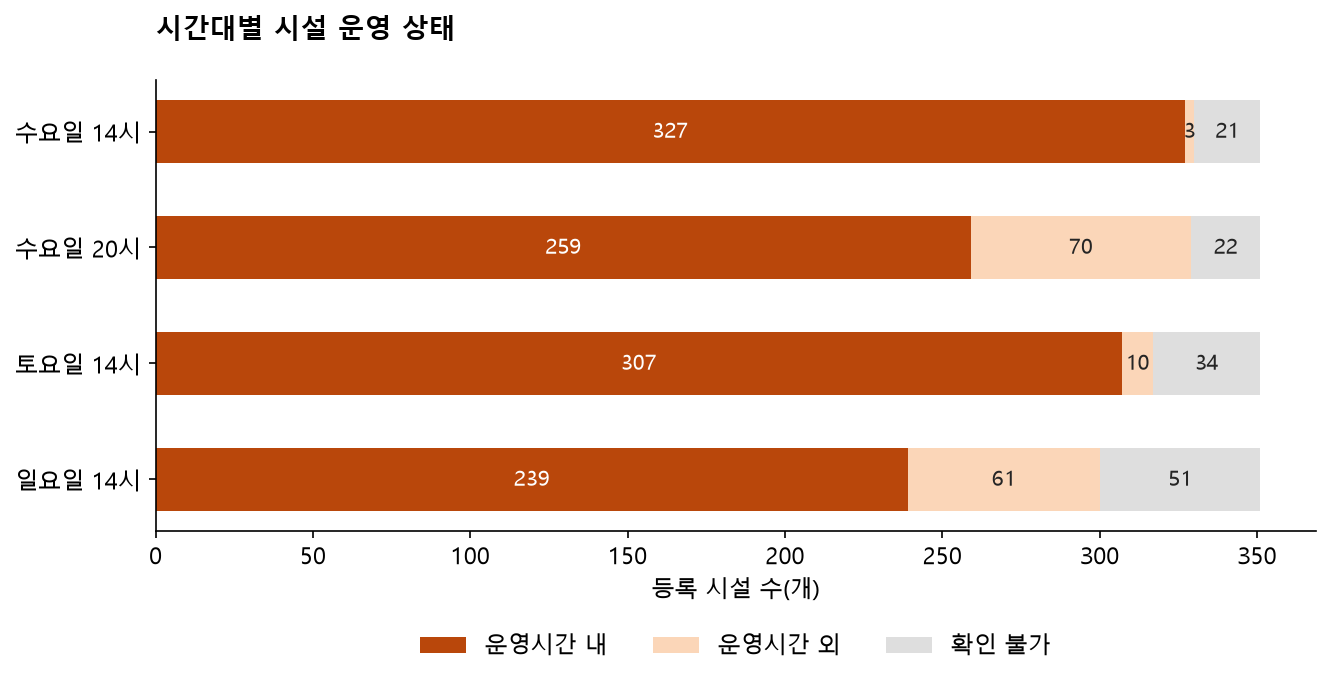

In [6]:
overall=counts[counts.kind=='전체'].copy()
overall['upper']=overall.open+overall.unknown
overall['open_pct_of_registered']=100*overall.open/overall.total
display(overall[['label','total','open','closed','unknown','upper','open_pct_of_registered']].round(2))
display(Image(filename=str(ROOT/'dist/figures/scenario_counts.png')))


In [7]:
d=overall.set_index('scenario');night=d.loc['wed20'];day=d.loc['wed14'];sun=d.loc['sun14']
display(Markdown(f"**해석.** 분석 {audit['primary']}개에서 수요일14시 {int(day.open)}개, 20시 {int(night.open)}개가 운영시간에 포함된다. 저녁의 확인된 개방 수는 낮의 {100*night.open/day.open:.1f}%다. 저녁 미확정 {int(night.unknown)}개를 고려한 범위는 {int(night.open)}~{int(night.upper)}개다. 일요일은 {int(sun.open)}~{int(sun.upper)}개로 범위가 겹치므로, 전체 종목에서 저녁보다 일요일이 반드시 더 불리하다고 단정하지 않는다."))


**해석.** 분석 351개에서 수요일14시 327개, 20시 259개가 운영시간에 포함된다. 저녁의 확인된 개방 수는 낮의 79.2%다. 저녁 미확정 22개를 고려한 범위는 259~281개다. 일요일은 239~290개로 범위가 겹치므로, 전체 종목에서 저녁보다 일요일이 반드시 더 불리하다고 단정하지 않는다.

## 5. 종목별 차이: 일요일 수영장

전체 시설 수는 야외 구기장과 수영장의 다른 운영구조를 가릴 수 있다. 동일한 시설유형끼리 시간대를 비교한다.


total                    open                   unknown              \
scenario sat14 sun14 wed14 wed20 sat14 sun14 wed14 wed20   sat14 sun14 wed14   
kind                                                                           
농구장         40    40    40    40    37    34    38    28       3     4     2   
배드민턴장       70    70    70    70    61    56    65    59       8     8     4   
수영장         91    91    91    91    75    17    87    79       7    25     4   
축구장         57    57    57    57    52    50    51    30       5     5     5   
테니스장        64    64    64    64    57    57    60    45       7     5     3   
풋살장         29    29    29    29    25    25    26    18       4     4     3   

                
scenario wed20  
kind            
농구장          2  
배드민턴장        4  
수영장          4  
축구장          6  
테니스장         3  
풋살장          3

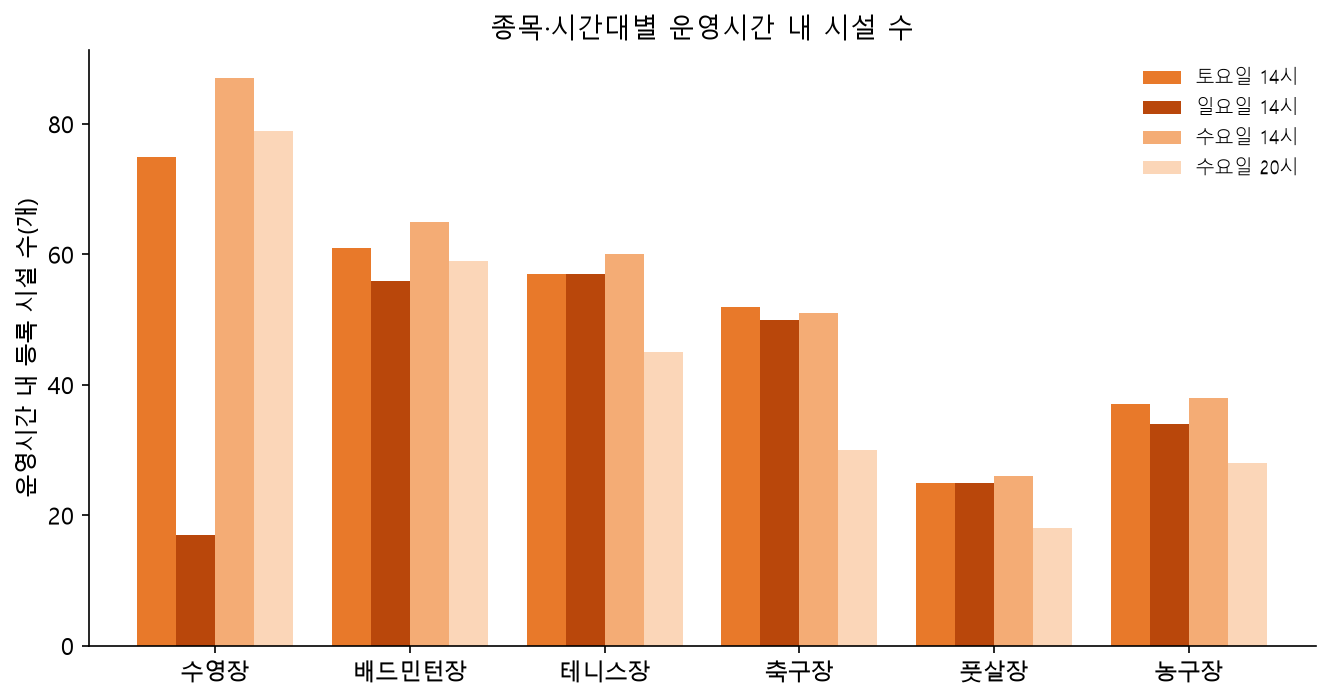

**해석.** 수영장 91개 중 수요일20시는 79개, 일요일14시는 17개가 운영시간 내다. 일요일 시간 외49개·미확정25개다. 미확정이 모두 열린다고 가정해도 42개로 평일 저녁의 확인된 공급보다 적다. 종목별 운영체계와 주차별 휴관을 확인할 필요가 있다. 수영 강습과 자유수영 가능 시간은 별도로 구분하지 못했다.

In [8]:
display(counts[counts.kind!='전체'].pivot(index='kind',columns='scenario',values=['total','open','unknown']))
display(Image(filename=str(ROOT/'dist/figures/by_sport.png')))
sw=counts[counts.kind=='수영장'].set_index('scenario')
s=sw.loc['sun14'];w=sw.loc['wed20']
display(Markdown(f"**해석.** 수영장 {int(s.total)}개 중 수요일20시는 {int(w.open)}개, 일요일14시는 {int(s.open)}개가 운영시간 내다. 일요일 시간 외{int(s.closed)}개·미확정{int(s.unknown)}개다. 미확정이 모두 열린다고 가정해도 {int(s.open+s.unknown)}개로 평일 저녁의 확인된 공급보다 적다. 종목별 운영체계와 주차별 휴관을 확인할 필요가 있다. 수영 강습과 자유수영 가능 시간은 별도로 구분하지 못했다."))


## 6. 공간 시각화: 시설 밀도와 시간대별 접근성 비교

지도는 같은 범례로 잠재 접근성·수요일20시·일요일14시를 비교한다. 극단값 때문에 대부분이 같은 색으로 보이지 않도록 잠재 접근성의98백분위에서 색상을 포화한다. 산출값 자체는 절단하지 않는다.


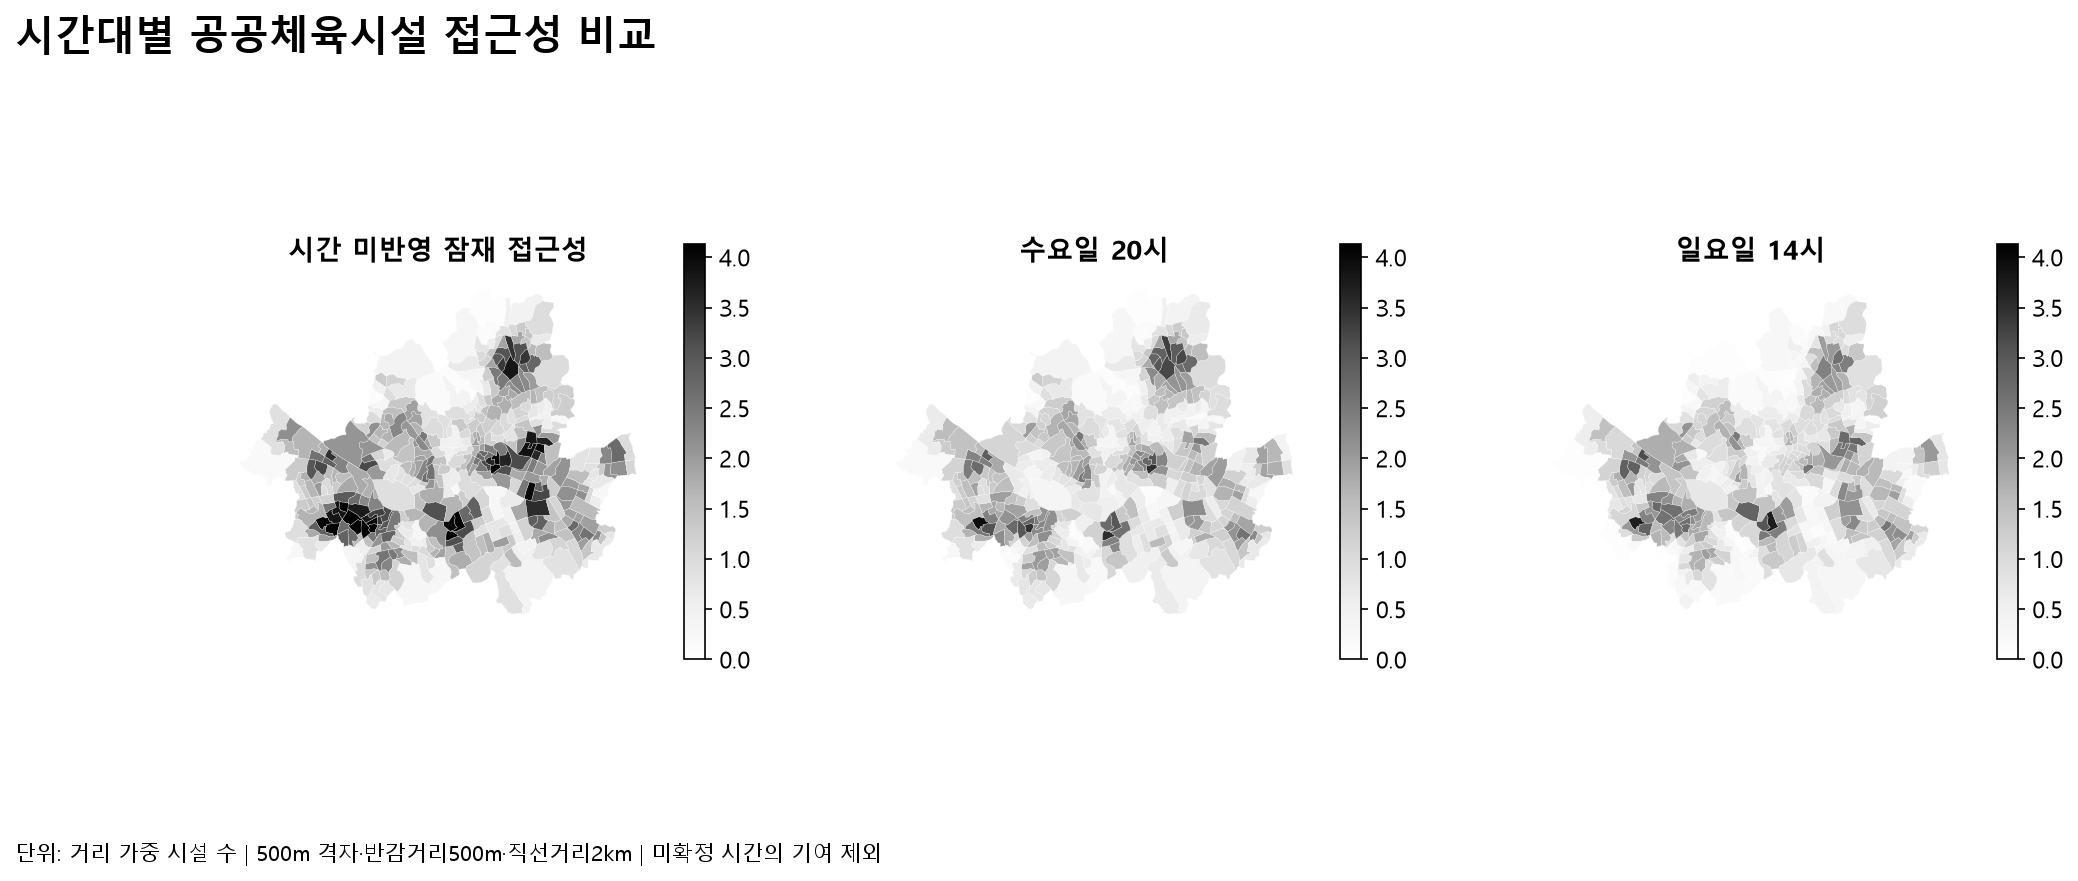

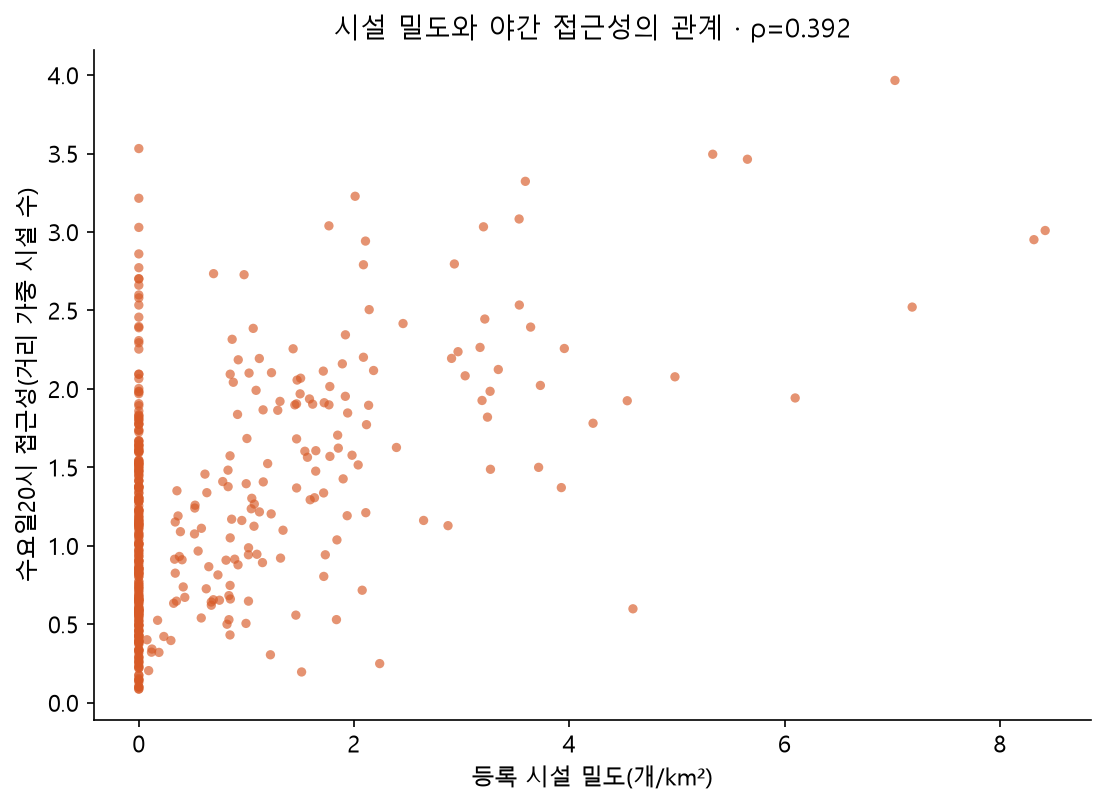

,density_vs_access_spearman,potential_vs_access_spearman
wed14,0.440583,0.988451
wed20,0.391710,0.869603
sat14,0.434810,0.962009
sun14,0.401362,0.894715


In [9]:
display(Image(filename=str(ROOT/'dist/figures/access_maps.png')))
display(Image(filename=str(ROOT/'dist/figures/density_access.png')))
display(pd.DataFrame(audit['correlations']).T)


In [10]:
dt=districts[(districts.kind=='전체')&(districts.scenario=='wed20')].copy()
display(dt.sort_values('access',ascending=False)[['district','n','density','potential','access','access_upper','retention']].round(3))
c=audit['correlations']['wed20']
hi=dt.nlargest(3,'access');lo=dt.nsmallest(3,'access')
display(Markdown(f"**해석.** 행정동 등록 밀도와 수요일20시 접근성의 Spearman 순위상관은 {c['density_vs_access_spearman']:.3f}이다. 시간 미반영 접근성과20시 접근성은 {c['potential_vs_access_spearman']:.3f}로 더 유사하다. 즉 기본 입지 패턴이 상당 부분 유지되지만 모든 동네의 순위와 이용기회가 일치하지는 않는다. 밀도와 접근성은 경계·거리 처리부터 다르므로 두 지표 차이를 전부 시간 효과로 돌리지 않는다.\n\n자치구 격자 평균은 **{', '.join(hi.district)}**에서 상대적으로 높고 **{', '.join(lo.district)}**에서 낮다. 도심 경계 주변은 인접 동의 시설을 함께 이용할 가능성이 있고, 한강변 운동시설은 야간 운영시간·일조조건으로 기여가 달라질 수 있다는 해석이 가능하다. 이는 모형과 시설 위치에 근거한 가설이며, 토지이용·보행 경로·주민 수요의 인과효과를 검증한 결과는 아니다. 특히 산지가 포함된 저밀도 지역의 낮은 격자 평균을 주민의 부족 경험과 동일시하지 않는다."))


,district,n,density,potential,access,access_upper,retention
37,서대문구,11,0.632,1.799,1.592,1.594,0.885
28,성동구,18,1.077,2.518,1.588,1.762,0.630
41,구로구,19,0.946,2.081,1.574,1.758,0.756
39,양천구,12,0.677,1.915,1.449,1.619,0.756
48,송파구,25,0.744,1.817,1.429,1.508,0.786
35,노원구,20,0.564,1.523,1.407,1.454,0.924
29,광진구,18,1.021,2.300,1.393,1.624,0.606
26,중구,7,0.696,1.445,1.259,1.261,0.872
43,영등포구,19,0.786,2.097,1.123,1.288,0.536
40,강서구,24,0.579,1.298,1.088,1.179,0.838


**해석.** 행정동 등록 밀도와 수요일20시 접근성의 Spearman 순위상관은 0.392이다. 시간 미반영 접근성과20시 접근성은 0.870로 더 유사하다. 즉 기본 입지 패턴이 상당 부분 유지되지만 모든 동네의 순위와 이용기회가 일치하지는 않는다. 밀도와 접근성은 경계·거리 처리부터 다르므로 두 지표 차이를 전부 시간 효과로 돌리지 않는다.

자치구 격자 평균은 **서대문구, 성동구, 구로구**에서 상대적으로 높고 **강북구, 종로구, 은평구**에서 낮다. 도심 경계 주변은 인접 동의 시설을 함께 이용할 가능성이 있고, 한강변 운동시설은 야간 운영시간·일조조건으로 기여가 달라질 수 있다는 해석이 가능하다. 이는 모형과 시설 위치에 근거한 가설이며, 토지이용·보행 경로·주민 수요의 인과효과를 검증한 결과는 아니다. 특히 산지가 포함된 저밀도 지역의 낮은 격자 평균을 주민의 부족 경험과 동일시하지 않는다.

### 6.1. 행정동 비교와 도시 구조의 해석

전체 6종목·수요일 20시 기준으로 여섯 사례를 의도적으로 대비한다. 높은 밀도, 높은 접근성, 동 내부 시설이 없는 두 지역, 시간 제약, 넓은 행정구역을 살피는 사례이며 대표표본이 아니다. 순위는 427개 행정동의 내림차순·동률 공동순위다. 밀도 0인 동은 모두 공동 171위다. 접근성은 거리 가중 시설 수, 동 밖 기여율은 접근성에서 외부 시설이 차지하는 비중이며 실제 주민 이용률이 아니다.


,자치구,행정동,등록 수,면적(km²),밀도(개/km²),밀도 순위,저녁 접근성,접근성 순위,동 밖 기여율(0~1),계산지점 수
0,서초구,반포2동,10,1.187,8.421,1,3.009,12,0.103,6
1,구로구,고척2동,7,0.996,7.025,4,3.966,1,0.170,5
2,서초구,방배본동,0,0.659,0.000,171,3.532,2,1.000,1
3,은평구,구산동,0,1.352,0.000,171,0.086,427,1.000,5
4,마포구,망원1동,5,1.089,4.591,9,0.598,337,0.062,4
5,은평구,진관동,3,12.902,0.233,164,0.422,379,0.221,54


**행정경계 외부 시설의 접근성 기여**

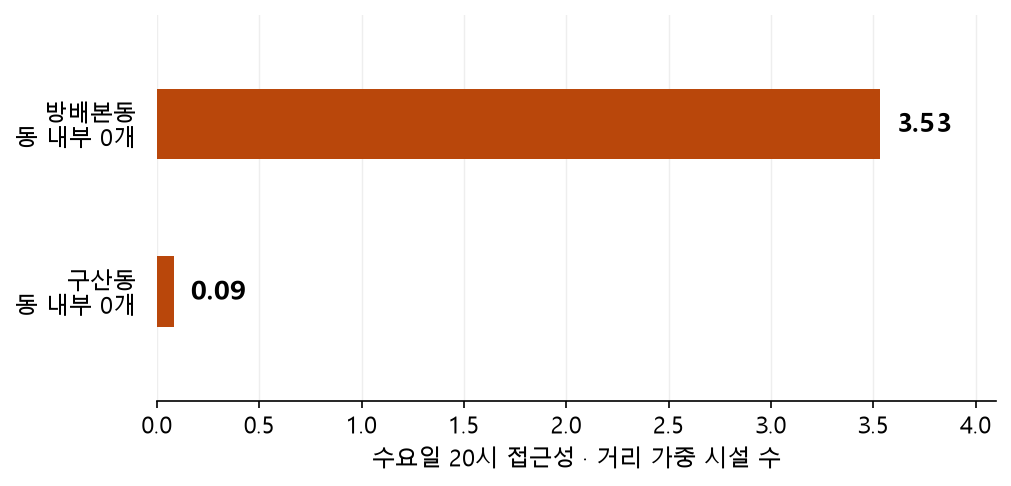

동 내부 시설이 모두 0개여도 주변 공급에 따라 저녁 접근성이 다르다. 방배본동은 계산지점 1개로 산출되어 위치 선택에 민감하다.

상세 해석: 방배본동과 구산동은 모두 분석 표본의 동 내부 시설이 0개여서 밀도가 0이다. 그러나 수요일 20시 접근성은 각각 3.53, 0.09로 다르다. 방배본동의 값은 전부 동 밖 시설에서 오며, 기여가 큰 시설은 서초구민체육센터 농구장(반포2동), 서초구민체육센터 수영장(반포2동), 반포종합운동장 농구장(반포2동)이다. 행정경계 안의 수만으로 주변 공급을 판단하면 이 차이가 사라진다. 다만 방배본동은 계산 격자점이 1개여서 위치 선택에 민감하며, 직선거리 모형이 실제 보행 연결성을 보장하지 않는다.

**공원·복합운동장의 종목시설 집중**

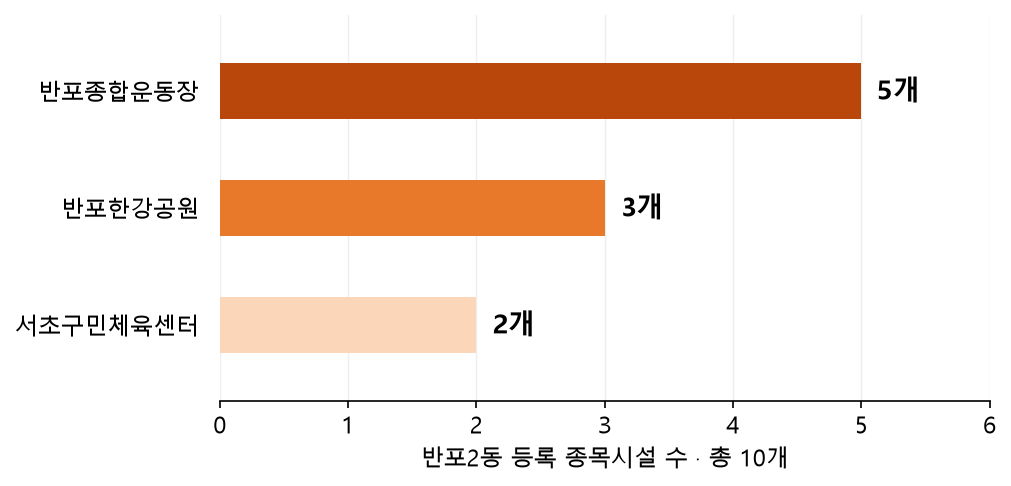

반포2동의 10개 종목시설은 세 시설명 그룹에 집중되어 있다. 시설명 기준의 분류이며 독립 건물 수·수용력을 뜻하지 않는다.

상세 해석: 반포2동의 10개 항목 중 5개는 반포종합운동장, 3개는 반포한강공원, 2개는 서초구민체육센터 이름으로 등록되어 있다. 높은 밀도는 10개의 독립적인 운동 거점보다 몇몇 거점에 여러 종목이 모인 구조를 반영한다. 고척2동도 7개 중 4개가 고척근린공원 이름의 종목시설이며, 이 4개는 원문에 24시간으로 표기되어 있다. 따라서 저녁 접근성 1위라는 결과를 이용 편의나 서비스 품질 1위로 읽을 수는 없다. 공원·체육거점의 복합 이용이라는 해석은 시설명과 위치 자료에 근거하며, 토지이용 면적이나 수용력을 측정한 결과는 아니다.

**한강공원 시설의 계절별 운영시간**

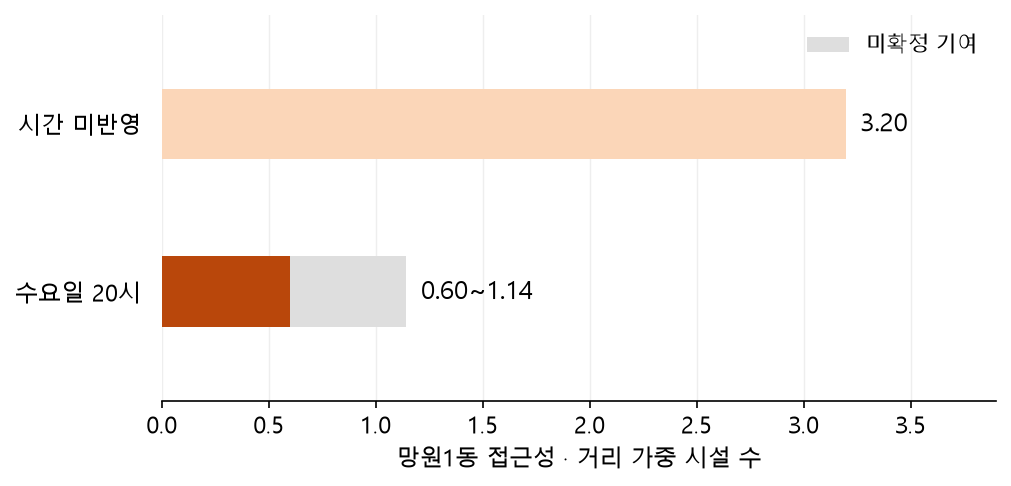

망원1동은 밀도 9위지만 저녁 접근성은 337위다. 한강공원 3개 종목시설은 10월 20시에 시간 외다. 회색 구간은 미확정 시설을 개방으로 가정할 때 추가되는 기여다.

상세 해석: 망원1동은 밀도 4.59개/km²로 427개 동 중 9위지만, 저녁 접근성은 0.60로 337위다. 잠재 접근성 3.20 대비 저녁 접근성 범위는 0.60~1.14, 유지율은 18.7~35.7%이다. 동 내부 5개 중 망원한강공원 농구장·축구장·테니스장은 10~3월 07~17시로 표기되어 20시에 시간 외이며, 수영장은 과거 개장예정 안내 때문에 미확정이다. 수변 공원에 여러 종목이 모여 있어도 계절별 시간 제약이 겹치면 저녁 공급이 줄어드는 사례이다. 야간 조명이나 소음이 단축 운영의 원인인지는 이 자료로 확인하지 못했다.

**행정구역 면적과 인구 비가중 평균의 영향**

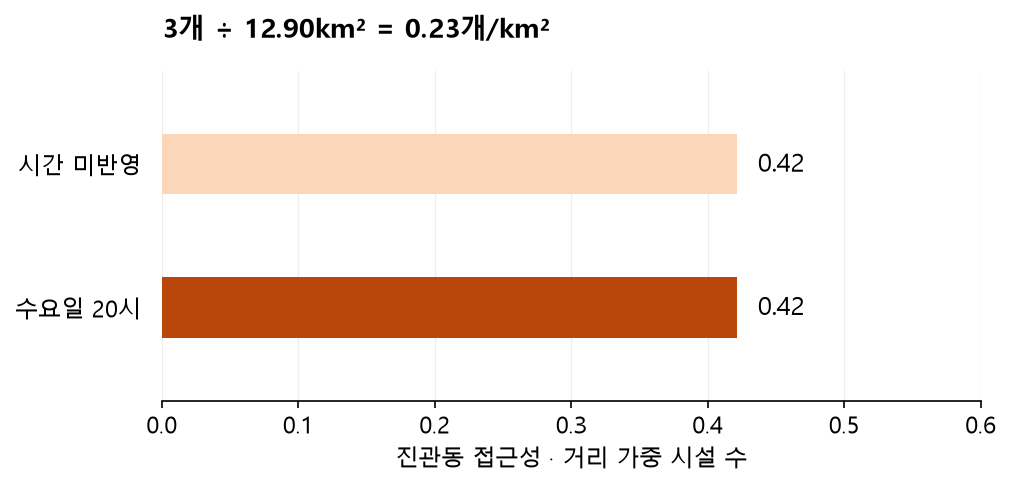

진관동은 저녁에도 잠재 접근성이 유지된다. 낮은 값은 시설 배치와 집계 범위를 함께 검토해야 한다. 54개 계산지점의 인구 비가중 평균이며 주민 평균 경험을 뜻하지 않는다.

상세 해석: 진관동은 분석 시설 3개, 경계 면적 12.90km²로 밀도가 0.23개/km²이다. 잠재 접근성과 저녁 접근성은 모두 0.42로, 이 모형에서는 저녁 폐쇄보다 기본적인 시설 배치·행정구역 범위의 영향이 먼저 드러난다. 54개 계산지점을 인구와 무관하게 평균하므로 사람이 적은 공간도 같은 비중으로 반영한다. 따라서 낮은 값을 주민 모두의 시설 부족으로 해석해서는 안 된다. 산지·주거지의 실제 비중과 시설 주변 인구를 확인하려면 토지피복·용도지역·인구 자료를 추가로 결합해야 한다.

,case_code,case_name,facility_id,facility_name,facility_dong,facility_district,contribution,outside,url
0,11220580,반포2동,1462,반포종합운동장 배드민턴장,반포2동,서초구,0.423355,False,https://sports.seoul.go.kr/main/facilities/fac...
1,11220580,반포2동,990,반포종합운동장 축구장,반포2동,서초구,0.423355,False,https://sports.seoul.go.kr/main/facilities/fac...
2,11220580,반포2동,1466,반포종합운동장 농구장,반포2동,서초구,0.423355,False,https://sports.seoul.go.kr/main/facilities/fac...
3,11220580,반포2동,991,반포종합운동장 테니스장,반포2동,서초구,0.423355,False,https://sports.seoul.go.kr/main/facilities/fac...
4,11220580,반포2동,1464,반포종합운동장 풋살경기장,반포2동,서초구,0.423355,False,https://sports.seoul.go.kr/main/facilities/fac...
5,11170620,고척2동,833,고척근린공원 운동장,고척2동,구로구,0.557560,False,https://sports.seoul.go.kr/main/facilities/fac...
6,11170620,고척2동,834,고척근린공원 테니스장,고척2동,구로구,0.557560,False,https://sports.seoul.go.kr/main/facilities/fac...
7,11170620,고척2동,841,구로구민체육센터 수영장,고척2동,구로구,0.557236,False,https://sports.seoul.go.kr/main/facilities/fac...
8,11170620,고척2동,1489,고척근린공원 농구장,고척2동,구로구,0.555782,False,https://sports.seoul.go.kr/main/facilities/fac...
9,11170620,고척2동,1488,고척근린공원 배드민턴장,고척2동,구로구,0.555782,False,https://sports.seoul.go.kr/main/facilities/fac...


In [11]:
cases=pd.DataFrame(payload['case_studies'])
case_columns={'district':'자치구','name':'행정동','n':'등록 수','area_km2':'면적(km²)','density':'밀도(개/km²)','density_rank':'밀도 순위','access':'저녁 접근성','access_rank':'접근성 순위','external_share':'동 밖 기여율(0~1)','grid_n':'계산지점 수'}
display(cases[list(case_columns)].rename(columns=case_columns).round(3))
for paragraph in payload['case_paragraphs']:
    display(Markdown('**'+paragraph['title']+'**'))
    display(Image(filename=str(ROOT/'dist/figures'/paragraph['figure'])))
    display(Markdown(paragraph['summary']+' '+paragraph['note']))
    display(Markdown('상세 해석: '+paragraph['text']))
display(pd.DataFrame(payload['case_contributions']))


**근거와 해석의 범위.** 사례의 수치, 동 밖 기여율, 기여 상위 시설은 동일한 거리 가중치를 시설별로 분해하여 계산했다. 전체 내부·외부 기여의 합은 기존 접근성 값과 일치한다. 표시하는 상위 5개 시설은 기여의 일부이며 전체 합계가 아니다. 시설의 공원·운동장·센터 이름과 등록 좌표·시간표를 이용해 거점 집중과 시간 제약을 설명했다. 토지이용 면적·산지 비중·주거인구를 새로 측정하거나 입지의 인과효과를 검증한 것은 아니다.

`data/processed/case_studies.csv`에 사례 지표를, `case_contributions.csv`에 사례별 기여 상위 5개 시설과 공식 상세 링크를 제공한다. `scripts/case_studies.py`에서 같은 원자료와 거리 가중치로 다시 생성한다.


## 7. 민감도 분석과 한계

거리 반감거리와 탐색반경,24시간 표기 시설, 과거 안내문구가 남은 시설의 포함 여부를 바꾸어 수요일20시 순위의 변화를 비교한다. ‘기본과 상관이 높다’는 것이 모든 지역의 순위나 정책 분류가 변하지 않는다는 뜻은 아니다.


In [12]:
display(pd.DataFrame(audit['sensitivity']).round(4))


,case,n,wed20_open,mean_grid_access,rank_corr_to_base
0,기본,351,259,1.0326,1.0000
1,거리감쇠1000m,351,259,2.1613,0.9701
2,반경1000m,351,259,0.5581,0.9139
3,24시간 표기 제외,295,203,0.8062,0.8654
4,과거 안내문구 제외,319,236,0.9428,0.9609


**해석의 범위와 후속 과제**

1. **등록표본·자료 최신성.** 포털의 매일 갱신은 시설별 현장확인과 다르다. 과거 방역·공사·개장예정 문구가 남아 있다. 원자료의 공공 분류를 따랐으며 법적 소유형태·전수성은 검증하지 않았다.
2. **이용 가능성.** 운영시간 내라도 강습·회원·연령·성별·장애·팀등록 제한, 비용, 추첨, 예약 마감으로 이용하지 못할 수 있다. 단순 시간 가중치는 정원·혼잡·서비스 품질을 반영하지 않는다. 무작위 시설 현장검증으로 일반화하지 않았다.
3. **거리·공간 단위.** 직선거리는 강·철도·경사·담장·출입구를 무시한다.500m 격자와2km 반경은 연구자 선택이다. 서울 외곽의 경기도 공급은 빠져 있다. 동 경계와 격자 선택에 따라 결과가 달라질 수 있다.
4. **수요.** 산지·수면을 포함하는 인구 비가중 격자 평균이므로 주민의 평균 경험이나 혜택을 받는 인구 비율로 읽을 수 없다. 근로자의 퇴근 후 생활권을 직접 관측한 것도 아니다.
5. **불확실성.** 하한·상한은 시간 판정만 대상으로 한다. 좌표 오류·미등록·노후화·수요 오차는 포함하지 않는다. 주차별 운영의 상한은 모든 시설이 동시에 여는 실제 날짜를 뜻하지 않는다.

**후속 연구 순서:** 운영기관별 최신 시간표 확인 → 예약 슬롯·자격·요금·이용률 연결 → 인구가중 및 보행 네트워크 접근성 → 수요·비용을 반영한 운영시간 연장과 신규입지 시나리오 비교.

**결론.** 시간 미반영 접근성과 저녁 접근성은 전반적으로 유사한 공간 패턴을 보인다. 다만 일요일 수영장과 일부 행정동에서는 운영시간에 따른 공급 감소가 나타나므로 종목·시간대별 분석이 필요하다.


## 8. 검증 및 재현 파일

아래 검증은 원본 해시, 종료시각·정비·주차별 휴관 의미, 모든 종목·시간 조합의 합계, 접근성 하한≤상한≤잠재값, 종목별 가산성, 자양3동의 독립 거리 재계산, 정책 후보 기준을 확인한다. 자료가 현재 실제 영업을 완벽히 반영한다는 검증은 아니다.


In [13]:
verify.main()
import platform,importlib.metadata
print('Python',platform.python_version())
for package in ['numpy','pandas','geopandas','shapely','pyproj','scipy','matplotlib','nbformat','nbclient']:
    print(package,importlib.metadata.version(package))


PASS: source hash, time semantics, all 28 strata, spatial bounds, type additivity, independent distance calculation, policy thresholds
Python 3.13.13
numpy 2.5.3
pandas 3.0.5
geopandas 1.1.4
shapely 2.1.2
pyproj 3.8.0
scipy 1.18.1
matplotlib 3.11.2
nbformat 5.11.1
nbclient 0.11.0


- `data/raw`: 수집 원본·시설 상세페이지·좌표·출처 해시
- `data/processed/facility_audit.csv`: 포함·제외 항목과 원문·판정 근거
- `data/processed/dong_metrics.csv`, `district_metrics.csv`: 종목·시간별 지표
- `data/processed/policy_candidates.csv`, `sensitivity.csv`: 후속 조사 분류·민감도
- `scripts`: 전처리·공간 계산·시간 판정·검증 코드
- `dist`: 인터랙티브 웹보고서·그림·CSV·실행 노트북·재현ZIP

제출 포털에는 자동 제출하지 않았다. 웹보고서의 열람 권한은 제출 전에 확인한다.
